# Analyze Diabetes Data

### How does the length of hospital stay differ between patients aged 30-40 and patients aged 70-80 in this dataset?

Supporting questions:
1. How many hospital encounters are recorded for each age group?
2. What is the average hospital stay in each group?
3. What is the median hospital stay in each group?
4. How much does hospital stay length vary within each group?
5. Which group has the longer average stay, and by how many days?

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/niteen11/DataAnalyticsAcademy/master/Python/dataset_diabetes/diabetic_data.csv")

In [3]:
df

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO


In [4]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [5]:
df.shape

(101766, 50)

In [6]:
df.dtypes

encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride         

In [7]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


# Cleaning Tasks

In [8]:
missing_data = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing_data = missing_data.sort_values(
    "Missing Values",
    ascending=False
)

missing_data

,Missing Values,Missing Percentage
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
encounter_id,0,0.00
nateglinide,0,0.00
glimepiride,0,0.00
acetohexamide,0,0.00
glipizide,0,0.00
glyburide,0,0.00
tolbutamide,0,0.00
pioglitazone,0,0.00


In [9]:
df_clean = df.copy()

df_clean['age'] = (
    df_clean['age']
    .astype('string')
    .str.strip()
    .replace('', pd.NA)
)

df_clean['time_in_hospital'] = pd.to_numeric(
    df_clean['time_in_hospital'],
    errors='coerce'
)

print("Missing values in required columns:")
print(df_clean[['age', 'time_in_hospital']].isna().sum())

Missing values in required columns:
age                 0
time_in_hospital    0
dtype: int64


<Axes: >

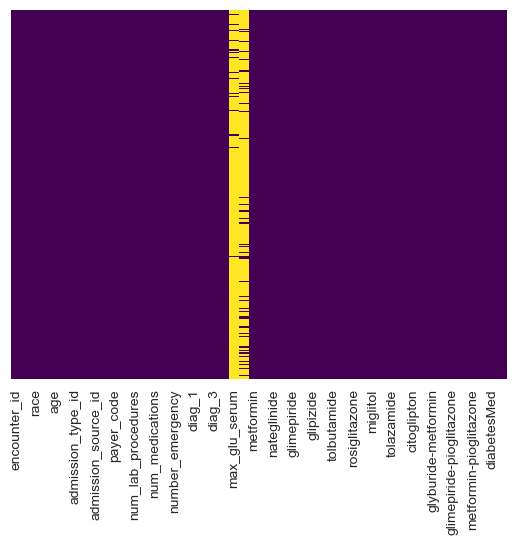

In [22]:
sns.heatmap(df_clean.isnull(),yticklabels=False,cbar=False,cmap="viridis")

# Group Filtering

<Axes: xlabel='age', ylabel='Count'>

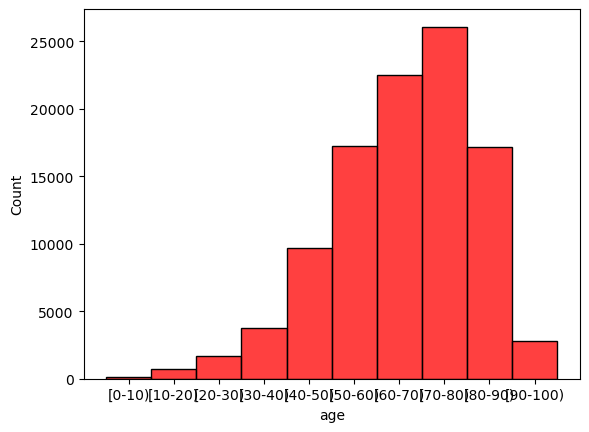

In [11]:
sns.histplot(df['age'].dropna(),kde=False,color="red",bins=40)

In [12]:
comparison_df = df_clean[df_clean["age"].isin(["[30-40)", "[70-80)"])]

In [13]:
age_groups = ['[30-40)', '[70-80)']

comparison_df = df_clean[
    df_clean['age'].isin(age_groups)
].copy()

# Use valid stay values for calculations and charts
stay_data = comparison_df.dropna(
    subset=['time_in_hospital']
).copy()

print(
    "Selected encounters missing hospital stay:",
    len(comparison_df) - len(stay_data)
)

Selected encounters missing hospital stay: 0


### 1: How many hospital encounters are recorded for each age group?

In [14]:
encounter_counts = (
    comparison_df.groupby('age')
    .size()
    .reindex(age_groups, fill_value=0)
    .reset_index(name='Hospital_Encounters')
)

encounter_counts

,age,Hospital_Encounters
0,[30-40),3775
1,[70-80),26068


### 2: What is the average hospital stay?

In [15]:
average_stay = (
    stay_data.groupby('age')['time_in_hospital']
    .mean()
    .round(2)
    .reset_index(name='Average_Stay_Days')
)

average_stay

,age,Average_Stay_Days
0,[30-40),3.80
1,[70-80),4.59


### 3: What is the median hospital stay?

In [16]:
median_stay = (
    stay_data.groupby('age')['time_in_hospital']
    .median()
    .reset_index(name='Median_Stay_Days')
)

median_stay

,age,Median_Stay_Days
0,[30-40),3.0
1,[70-80),4.0


### 4: How much does hospital stay length vary?

In [18]:
variation = (
    stay_data.groupby('age')['time_in_hospital']
    .agg(['std', 'min', 'max'])
    .round(2)
    .rename(columns={
        'std': 'Standard_Deviation_Days',
        'min': 'Minimum_Days',
        'max': 'Maximum_Days'
    })
)

variation

,Standard_Deviation_Days,Minimum_Days,Maximum_Days
age,,,
[30-40),2.69,1,14
[70-80),3.04,1,14


### 5: Which group has the longer average stay?

In [19]:
means = stay_data.groupby('age')['time_in_hospital'].mean()

difference = means['[70-80)'] - means['[30-40)']

if difference > 0:
    print(f"Ages 70–79 had a longer average stay by {difference:.2f} days.")
elif difference < 0:
    print(f"Ages 30–39 had a longer average stay by {abs(difference):.2f} days.")
else:
    print("Both groups had the same average hospital stay.")

Ages 70–79 had a longer average stay by 0.79 days.


# Visualization

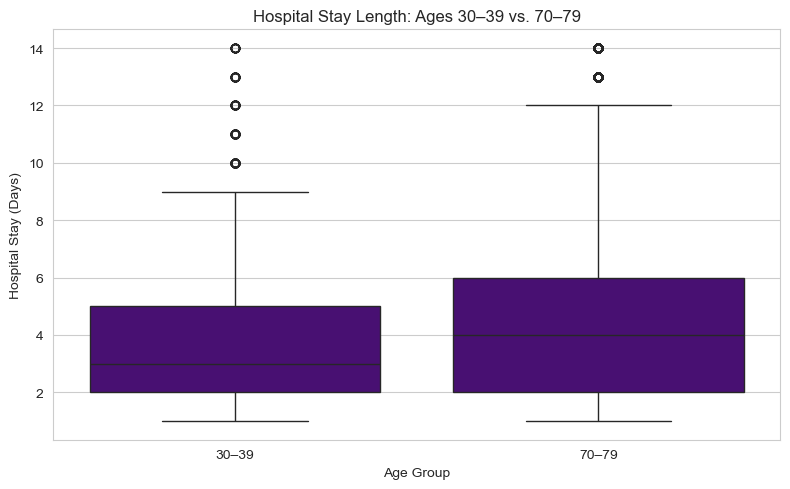

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=stay_data,
    x='age',
    y='time_in_hospital',
    order=age_groups,
    color='indigo'
)

plt.title('Hospital Stay Length: Ages 30–39 vs. 70–79')
plt.xlabel('Age Group')
plt.ylabel('Hospital Stay (Days)')
plt.xticks([0, 1], ['30–39', '70–79'])
plt.tight_layout()
plt.show()

<Axes: xlabel='time_in_hospital', ylabel='count'>

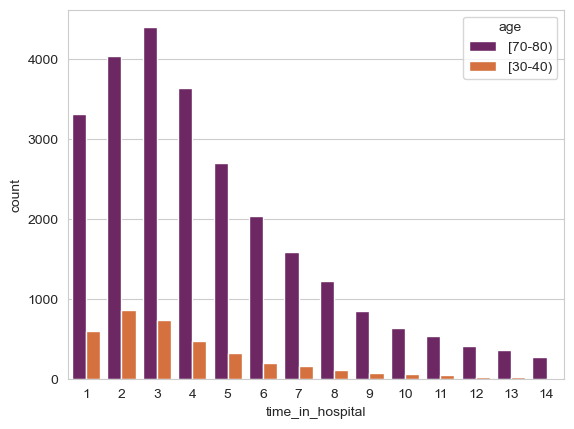

In [21]:
sns.set_style('whitegrid')
sns.countplot(x='time_in_hospital', hue='age', data=comparison_df,palette='inferno')

In [23]:
insulin_summary = (
    stay_data.groupby('insulin')['time_in_hospital']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

insulin_summary

,count,mean,median,std
insulin,,,,
Down,3357,5.04,4.0,3.16
No,14410,4.18,3.0,2.92
Steady,8927,4.49,4.0,2.92
Up,3149,5.35,5.0,3.28


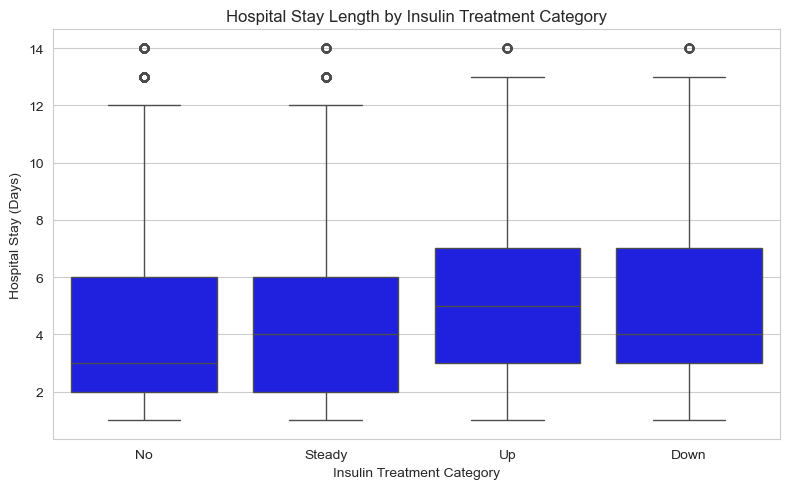

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=stay_data,
    x='insulin',
    y='time_in_hospital',
    order=['No', 'Steady', 'Up', 'Down'],
    color='blue'
)

plt.title('Hospital Stay Length by Insulin Treatment Category')
plt.xlabel('Insulin Treatment Category')
plt.ylabel('Hospital Stay (Days)')
plt.tight_layout()
plt.show()

In [23]:
readmission_summary = (
    stay_data.groupby('readmission')['time_in_hospital']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

insulin_summary

,count,mean,median,std
insulin,,,,
Down,3357,5.04,4.0,3.16
No,14410,4.18,3.0,2.92
Steady,8927,4.49,4.0,2.92
Up,3149,5.35,5.0,3.28


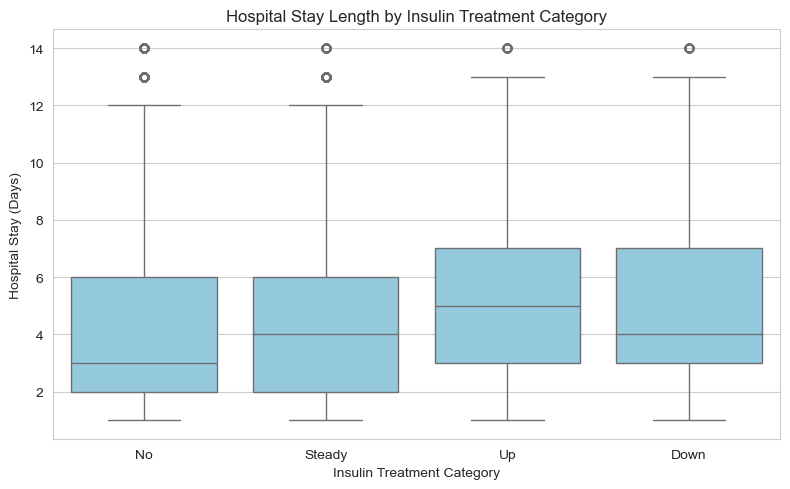

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=stay_data,
    x='insulin',
    y='time_in_hospital',
    order=['No', 'Steady', 'Up', 'Down'],
    color='skyblue'
)

plt.title('Hospital Stay Length by Insulin Treatment Category')
plt.xlabel('Insulin Treatment Category')
plt.ylabel('Hospital Stay (Days)')
plt.tight_layout()
plt.show()

,count,mean,median
readmitted,,,
NO,15688,4.39,4.0
>30,10662,4.51,4.0
<30,3493,4.89,4.0


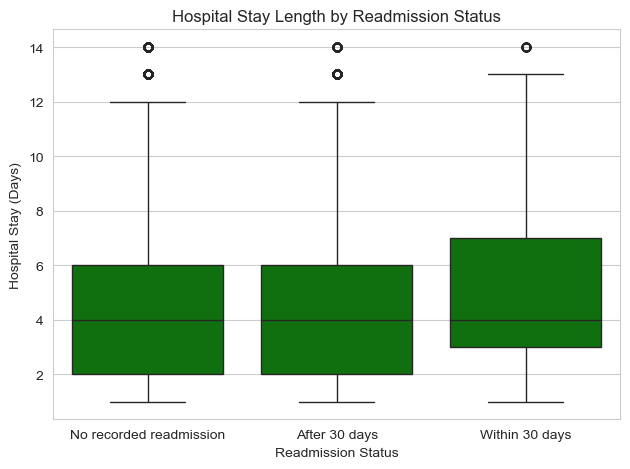

In [32]:
readmission_summary = (
    stay_data.groupby('readmitted')['time_in_hospital']
    .agg(['count', 'mean', 'median'])
    .reindex(['NO', '>30', '<30'])
    .round(2)
)

display(readmission_summary)

sns.boxplot(
    data=stay_data,
    x='readmitted',
    y='time_in_hospital',
    order=['NO', '>30', '<30'],
    color='green'
)

plt.title('Hospital Stay Length by Readmission Status')
plt.xlabel('Readmission Status')
plt.ylabel('Hospital Stay (Days)')
plt.xticks(
    [0, 1, 2],
    ['No recorded readmission', 'After 30 days', 'Within 30 days']
)
plt.tight_layout()
plt.show()

Hospital encounters for patient aged 30-40 had an average stay of 3.8 days, campared with 4.59 days for patients aged 70-80. The 70-80 ag group has a longer average stay by 0.79 days . The results decribes a difference betwee the groups but does not show that age caused it.